# 00 – Data Loading and Data Types

**Objective:** load the Madrid property sales dataset, get a first overview of its size and structure, review the data type of each column, and fix any type issues before saving the clean version.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style across all notebooks
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

# Human-readable period labels
PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

In [2]:
df = pd.read_csv("../data/Madrid_Sale.csv")
df.shape

(94815, 41)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 94815 entries, 0 to 94814
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ASSETID                        94815 non-null  str    
 1   PERIOD                         94815 non-null  int64  
 2   PRICE                          94815 non-null  float64
 3   UNITPRICE                      94815 non-null  float64
 4   CONSTRUCTEDAREA                94815 non-null  int64  
 5   ROOMNUMBER                     94815 non-null  int64  
 6   BATHNUMBER                     94815 non-null  int64  
 7   HASTERRACE                     94815 non-null  int64  
 8   HASLIFT                        94815 non-null  int64  
 9   HASAIRCONDITIONING             94815 non-null  int64  
 10  AMENITYID                      94815 non-null  int64  
 11  HASPARKINGSPACE                94815 non-null  int64  
 12  ISPARKINGSPACEINCLUDEDINPRICE  94815 non-null  int64  
 1

In [4]:
df.dtypes.value_counts()

int64      29
float64    11
str         1
Name: count, dtype: int64

In [5]:
df.head(3)

,ASSETID,PERIOD,PRICE,UNITPRICE,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,HASTERRACE,HASLIFT,HASAIRCONDITIONING,AMENITYID,HASPARKINGSPACE,ISPARKINGSPACEINCLUDEDINPRICE,PARKINGSPACEPRICE,HASNORTHORIENTATION,HASSOUTHORIENTATION,HASEASTORIENTATION,HASWESTORIENTATION,HASBOXROOM,HASWARDROBE,HASSWIMMINGPOOL,HASDOORMAN,HASGARDEN,ISDUPLEX,ISSTUDIO,ISINTOPFLOOR,CONSTRUCTIONYEAR,FLOORCLEAN,FLATLOCATIONID,CADCONSTRUCTIONYEAR,CADMAXBUILDINGFLOOR,CADDWELLINGCOUNT,CADASTRALQUALITYID,BUILTTYPEID_1,BUILTTYPEID_2,BUILTTYPEID_3,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,DISTANCE_TO_CASTELLANA,LONGITUDE,LATITUDE
0,A15019136831406238029,201803,126000.0,2680.851064,47,1,1,0,1,1,3,0,0,1,0,0,0,0,1,1,1,1,1,0,0,0,2005.0,1.0,1.0,2005,7,319,3.0,0,1,0,8.058429,0.872075,6.868677,-3.766933,40.362485
1,A6677225905472065344,201803,235000.0,4351.851852,54,1,1,0,0,0,3,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,NaN,1.0,2.0,1900,5,11,3.0,0,0,1,0.876369,0.116382,1.544125,-3.710725,40.422430
2,A13341979748618524775,201803,373000.0,4973.333333,75,2,1,0,0,1,3,0,0,1,0,1,0,0,1,1,0,0,0,0,0,0,NaN,3.0,1.0,1915,6,26,3.0,0,0,1,0.907479,0.139109,1.608444,-3.711571,40.422190


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PERIOD,94815.0,201808.613289,3.684625,201803.000000,201806.000000,201809.000000,201812.000000,2.018120e+05
PRICE,94815.0,396110.109160,417074.407623,21000.000000,160000.000000,262000.000000,467000.000000,8.133000e+06
UNITPRICE,94815.0,3661.051534,1700.499398,805.309735,2240.000000,3480.000000,4744.623034,9.997561e+03
CONSTRUCTEDAREA,94815.0,101.397163,67.078259,21.000000,62.000000,83.000000,117.000000,9.850000e+02
ROOMNUMBER,94815.0,2.580900,1.244878,0.000000,2.000000,3.000000,3.000000,9.300000e+01
BATHNUMBER,94815.0,1.585456,0.843024,0.000000,1.000000,1.000000,2.000000,2.000000e+01
HASTERRACE,94815.0,0.355260,0.478595,0.000000,0.000000,0.000000,1.000000,1.000000e+00
HASLIFT,94815.0,0.695597,0.460157,0.000000,0.000000,1.000000,1.000000,1.000000e+00
HASAIRCONDITIONING,94815.0,0.448600,0.497354,0.000000,0.000000,0.000000,1.000000,1.000000e+00
AMENITYID,94815.0,2.922660,0.314865,1.000000,3.000000,3.000000,3.000000,3.000000e+00


In [7]:
# Check low-cardinality columns
for col in df.columns:
    n = df[col].nunique(dropna=False)
    if n <= 10:
        print(f"{col} ({n} unique): {sorted(df[col].dropna().unique())}")

PERIOD (4 unique): [np.int64(201803), np.int64(201806), np.int64(201809), np.int64(201812)]
HASTERRACE (2 unique): [np.int64(0), np.int64(1)]
HASLIFT (2 unique): [np.int64(0), np.int64(1)]
HASAIRCONDITIONING (2 unique): [np.int64(0), np.int64(1)]
AMENITYID (3 unique): [np.int64(1), np.int64(2), np.int64(3)]
HASPARKINGSPACE (2 unique): [np.int64(0), np.int64(1)]
ISPARKINGSPACEINCLUDEDINPRICE (2 unique): [np.int64(0), np.int64(1)]
HASNORTHORIENTATION (2 unique): [np.int64(0), np.int64(1)]
HASSOUTHORIENTATION (2 unique): [np.int64(0), np.int64(1)]
HASEASTORIENTATION (2 unique): [np.int64(0), np.int64(1)]
HASWESTORIENTATION (2 unique): [np.int64(0), np.int64(1)]
HASBOXROOM (2 unique): [np.int64(0), np.int64(1)]
HASWARDROBE (2 unique): [np.int64(0), np.int64(1)]
HASSWIMMINGPOOL (2 unique): [np.int64(0), np.int64(1)]
HASDOORMAN (2 unique): [np.int64(0), np.int64(1)]
HASGARDEN (2 unique): [np.int64(0), np.int64(1)]
ISDUPLEX (2 unique): [np.int64(0), np.int64(1)]
ISSTUDIO (2 unique): [np.int64

In [8]:
# Check duplicates and leakage
print(f"Unique ASSETIDs: {df['ASSETID'].nunique():,}")
print(f"Total rows:      {len(df):,}")
print(f"Duplicates:      {df['ASSETID'].duplicated().sum():,}")
print(f"\nUNITPRICE == PRICE / CONSTRUCTEDAREA?")
print(f"Max difference: {(df['UNITPRICE'] - df['PRICE'] / df['CONSTRUCTEDAREA']).abs().max():.2e}")

Unique ASSETIDs: 75,804
Total rows:      94,815
Duplicates:      19,011

UNITPRICE == PRICE / CONSTRUCTEDAREA?
Max difference: 6.37e-12


### Findings and actions

**What we see**
- The dataset contains **94,815 rows and 41 columns**: 11 `float64`, 29 `int64` and 1 `object` (`ASSETID`).
- The data is already mostly numeric and clean: there are no currency symbols, no text-encoded booleans and no empty columns.
- **17 binary features** (all `HAS*` and `IS*` columns) are properly coded as 0/1 integers.

**Problems detected**
- **`UNITPRICE` is target leakage:** it equals `PRICE / CONSTRUCTEDAREA` exactly (max difference ~10⁻¹²). Including it as a feature would give the model direct access to the target. It must be excluded.
- **~19,000 duplicate `ASSETID`s:** ~19,000 repeated ASSETIDs: 94,815 rows but only 75,804 unique properties. All repetitions occur within the same quarter, and in most cases the repeated rows describe the same flat (same area, rooms and location) with a different price, i.e. price updates of the same listing. To be investigated and treated in notebook 01.
- **`CONSTRUCTIONYEAR`** has 59% missing values and contains erroneous entries (values like 1, 50, 2291). The cadastral alternative `CADCONSTRUCTIONYEAR` is 100% complete (range 1623–2018).
- **`PERIOD`** Q4 2018 contains 44,270 listings, between 2 and 3.5 times more than the other quarters (12,652–21,920). This may reflect a change in data collection rather than a real market effect, so PERIOD must be taken into account in the analysis.”

**Actions**
1. Convert `PERIOD` to string (categorical).
2. Save the dataset with correct types. Leave duplicate removal, missing value treatment, and leakage column removal for notebook 01.

## Fixing data types

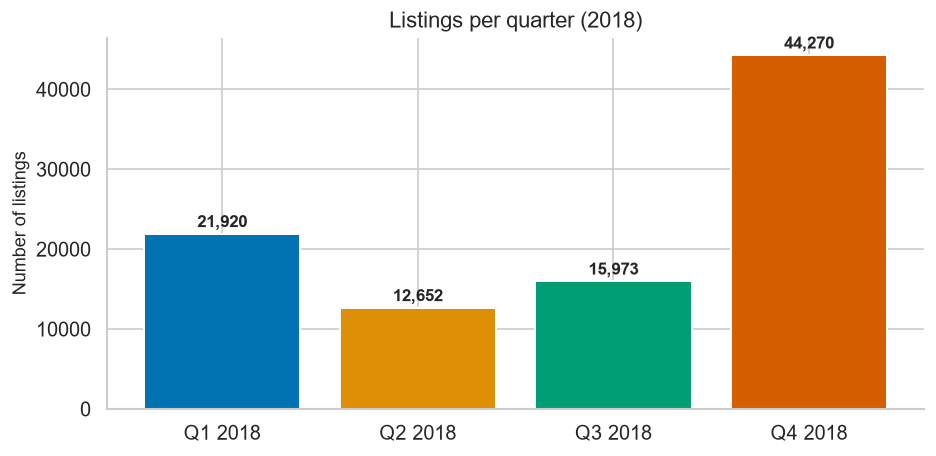

PERIOD dtype: str


In [9]:
df["PERIOD"] = df["PERIOD"].astype(str)

# Show distribution with readable labels
period_counts = df["PERIOD"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    [PERIOD_MAP[p] for p in period_counts.index],
    period_counts.values,
    color=sns.color_palette("colorblind", 4),
    edgecolor="white", linewidth=1.2
)
for bar, val in zip(bars, period_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 400,
            f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("Number of listings")
ax.set_xlabel("")
ax.set_title("Listings per quarter (2018)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"PERIOD dtype: {df['PERIOD'].dtype}")

In [10]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_parquet("../data/processed/listings_00.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 94815 rows × 41 columns


## Summary and next steps

**Actions performed in this notebook**
- Loaded the Madrid property sales dataset: **94,815 listings × 41 columns**, covering 4 quarterly snapshots in 2018.
- Converted `PERIOD` from integer to string (categorical).
- Identified key issues for the next notebooks: ~19K duplicate ASSETIDs, `UNITPRICE` as target leakage, `CONSTRUCTIONYEAR` with 59% missing and erroneous values.
- Saved the result to `data/processed/listings_00.parquet`.

**First observations about the target (`PRICE`)**
- All 94,815 listings have a price (no missing target).
- The median sale price is **262,000 €**, the mean is **396,000 €** and the maximum is **8,133,000 €**. The distribution is strongly right-skewed, suggesting a log transformation for modelling.